# Este Notebook es para ciertas cosas que nos referimos dentro del informe final! :)

## **Paso 3– preprocesamiento del texto**


#### ***Carga de los datos***

Primero importamos las librerias que utilizaremos durante el trabajo y cargamos nuestro corpus

Antes de realizar alguna modificación, creamos una copia de los datos para conservar el DataFrame original y asi evitar perder información durante el preprocesamiento

In [15]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

import matplotlib.pyplot as plt  # es para la parte 6

# cargamos los datos originales
df_original = pd.read_csv("../data/bbc_data.csv")

# creamos una copia para trabajar
df = df_original.copy()

# guardamos la copia en la carpeta data
df.to_csv("../data/bbc_data_copia.csv", index = False)


### ***Limpieza de los datos***

- Antes de trabajar con el contenido de las noticias revisamos
si existen valores nulos o documentos repetidos. Decidimos eliminar estos registros para evitar que una misma noticia
tenga mayor influencia en nuestro analisis por aparecer mas de una vez

In [16]:
# revisamos los datos antes de limpiarlos
print("Documentos originales:", len(df))
print("Valores nulos:", df.isnull().sum().sum())
print("Documentos duplicados:", df.duplicated(subset = ["data"]).sum())

# eliminamos valores nulos y noticias repetidas
df = df.dropna(subset = ["data", "labels"])
df = df.drop_duplicates(subset = ["data"])
df = df.reset_index(drop = True)

# guardamos los cambios en nuestra copia
df.to_csv("../data/bbc_data_copia.csv", index = False)

print("Documentos eliminados:", len(df_original) - len(df))
print("Documentos finales:", len(df))

Documentos originales: 2225
Valores nulos: 0
Documentos duplicados: 99
Documentos eliminados: 99
Documentos finales: 2126


### ***Separación de documentos y categorias***

- Separamos el contenido de las noticias de sus respectivas categorias, ya que para construir nuestra matriz solamente necesitamos trabajar con el texto
- Las categorias las guardaremos para mas adelante comparar los resultados obtenidos mediante SVD

In [17]:
# separamos las noticias de sus categorias
documentos = df["data"].tolist()
categorias = df["labels"].to_numpy()

print("Cantidad de documentos:", len(documentos))
print("Categorias:", np.unique(categorias))

Cantidad de documentos: 2126
Categorias: ['business' 'entertainment' 'politics' 'sport' 'tech']



Nos permite realizar el analisis sin utilizar las categorias, ya que nuestra idea es observar si las noticias  se agrupan por si solas segun su contenido

### ***Preprocesamiento y TF-IDF***

Para construir nuestro vocabulario necesitamos quedarnos con las palabras que sean mas relevantes para nuestro analisis

para esto decidimos:

- Convertir todas las palabras a minusculas
- Separar los textos en palabras de al menos dos letras
- Eliminar las stopwords del ingles
- Eliminar palabras que aparecen en menos de 3 documentos
- Eliminar palabras que aparecen en mas del 85% de los documentos

Utilizamos TF-IDF en lugar de trabajar directamente con la frecuencia de las palabras, porque nos permite darle mayor importancia a las que ayudan a diferenciar las noticias

Tambien utilizamos la normalización L2 para que las diferencias en la longitud de las noticias tengan menos influencia en el analisis

In [18]:
# configuramos TF-IDF
vectorizador = TfidfVectorizer(
    lowercase = True,
    stop_words = "english",
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    min_df = 3,
    max_df = 0.85,
    norm = "l2"
)

# aplicamos TF-IDF a las noticias
X = vectorizador.fit_transform(documentos)

# obtenemos nuestro vocabulario
vocabulario = vectorizador.get_feature_names_out()

print("Tamaño del vocabulario:", len(vocabulario))
print("Primeras 20 palabras:")
print(vocabulario[:20])

Tamaño del vocabulario: 12369
Primeras 20 palabras:
['aaa' 'aaas' 'aaron' 'abandon' 'abandoned' 'abandoning' 'abandonment'
 'abba' 'abbas' 'abbasi' 'abbott' 'abc' 'aberdeen' 'abeyie' 'abide'
 'abiding' 'abilities' 'ability' 'able' 'abn']


Luego de aplicar TF-IDF obtenemos nuestro vocabulario final compuesto por 12369 palabras que cumplen los criterios que definimos anteriormente

La idea de realizar este preprocesamiento es quedarnos con las palabras que realmente nos aportan información ya que esperamos que las noticias de una misma categoria tengan palabras en comun

## **Paso 4 – Construcción de la matriz textual**

### ***Construcción de la matriz A***

Ahora que tenemos nuestro vocabulario y los valores de TF-IDF podemos construir la matriz con la que trabajaremos

Como scikit-learn nos entrega los documentos en las filas y las palabras en las columnas, tenemos que transponer la matriz para obtener lo que nos pide el enunciado

**A pertenece R^(mxn)**

Donde:

- $m$: cantidad de palabras de nuestro vocabulario
- $n$: cantidad de noticias
- Cada entrada de A corresponde al peso TF-IDF de una palabra dentro de una noticia

In [19]:
# transponemos la matriz
A = X.T.tocsr()

# obtenemos sus dimensiones
m, n = A.shape

print("Dimensiones de A:", A.shape)
print("Cantidad de terminos:", m)
print("Cantidad de documentos:", n)
print("Entradas distintas de cero:", A.nnz)

Dimensiones de A: (12369, 2126)
Cantidad de terminos: 12369
Cantidad de documentos: 2126
Entradas distintas de cero: 278822


- Ya tenemos nuestra matriz A con las palabras en las filas y las noticias en las columnas

- Como no todas las palabras aparecen en todas las noticias, gran parte de nuestra matriz esta compuesta por ceros. Por esto decidimos trabajar con una matriz dispersa, para asi evitar almacenar todos estos ceros de manera innecesaria


### ***Visualización de la matriz***

Como la matriz es bastante grande, solo mostraremos las 10 palabras con mayor peso TF-IDF acumulado en los primeros 5 documentos para asi tener una idea de como quedo construida

In [20]:
# seleccionamos las 10 palabras con mayor peso
indices = np.argsort( A[:, :5].toarray().sum(axis = 1))[-10:][::-1]

# mostramos una parte de nuestra matriz
pd.DataFrame(A[indices, :5].toarray(), index = vocabulario[indices], columns = ["Doc 1", "Doc 2", "Doc 3", "Doc 4", "Doc 5"]).round(4)

,Doc 1,Doc 2,Doc 3,Doc 4,Doc 5
oceans,0.0000,0.0000,0.0000,0.2355,0.4769
musicians,0.5005,0.0000,0.0000,0.0000,0.0000
doherty,0.0000,0.0000,0.4735,0.0000,0.0000
carrey,0.0000,0.0000,0.0000,0.4711,0.0000
sequel,0.0000,0.0000,0.0000,0.0000,0.3604
band,0.0000,0.3002,0.0513,0.0000,0.0000
starring,0.0000,0.0000,0.0000,0.1580,0.1919
number,0.0000,0.0669,0.0305,0.1698,0.0688
chart,0.0000,0.0405,0.0000,0.2314,0.0625
box,0.0000,0.0000,0.0000,0.1390,0.1689


- Podemos observar que cuando una palabra no aparece en una noticia, su valor es 0, en caso contrario tenemos el peso que le asigno TF-IDF

- De esta manera pasamos de tener noticias en formato de texto a tener una representación numerica

## **Paso 5 – Calculo de la SVD**

### ***Descomposición en valores singulares***

Ahora que tenemos la matriz A podemos aplicar la descomposición SVD

Recordemos que A = U · Σ · Vᵀ

Donde:
- U: contiene los vectores singulares izquierdos
- Σ: matriz diagonal que contiene los valores singulares
- V: contiene los vectores singulares derechos

Utilizaremos NumPy con el parametro `full_matrices=False`, ya que no necesitamos almacenar vectores adicionales para representar nuestra matriz

Tambien debemos pasar nuestra matriz dispersa a una matriz densa para poder utilizar este metodo

In [21]:
# calculamos la SVD de nuestra matriz A
U, s, Vt = np.linalg.svd( A.toarray(), full_matrices = False)

# obtenemos Sigma y V
Sigma = np.diag(s)
V = Vt.T

# mostramos las dimensiones
print("Dimensiones de A:", A.shape)
print("Dimensiones de U:", U.shape)
print("Dimensiones de Sigma:", Sigma.shape)
print("Dimensiones de V:", V.shape)
print("Cantidad de valores singulares:", len(s))

Dimensiones de A: (12369, 2126)
Dimensiones de U: (12369, 2126)
Dimensiones de Sigma: (2126, 2126)
Dimensiones de V: (2126, 2126)
Cantidad de valores singulares: 2126


Luego de aplicar SVD obtenemos las matrices U, Σ y V, con las cuales podemos representar nuestra matriz A

Si consideramos r = min(m,n), las dimensiones de nuestras matrices quedan de la siguiente manera:


Si consideramos r = min(m,n), las dimensiones de nuestras
matrices quedan de la siguiente manera:

- A: 12369 x 2126
- U: 12369 x 2126
- Σ: 2126 x 2126
- V: 2126 x 2126

La idea de realizar esta descomposición es que mas adelante podamos trabajar con menos componentes sin perder demasiada información de nuestra matriz

Con esto podremos analizar si las noticias se agrupan segun su contenido, como planteamos en nuestra hipotesis inicial

### ***Valores singulares***

Antes de decidir con cuantas componentes nos quedaremos veamos los primeros 10 valores singulares que obtuvimosal aplicar SVD

In [22]:
# mostramos los primeros 10 valores singulares
print(s[:10])

[7.54445398 4.79812001 4.32966286 4.08820491 3.89337884 3.40298315
 3.14515989 3.08270004 3.04091875 2.95077703]


Podemos observar que los valores singulares estan ordenados de mayor a menor. Mientras mayor sea el valor singular, mayor sera el aporte de su componente a la información de nuestra matriz, medido a traves de la norma de Frobenius. Por ahora nos quedaremos con todos los valores singulares, porque en el siguiente paso veremos cuantos nos conviene utilizar

### ***Verificación de la SVD***

Para ver si realizamos correctamente la descomposición, reconstruiremos una pequeña parte de nuestra matriz A y la compararemos con la original. La idea es calcular la norma de la diferencia entre ambas matrices y obtener un error lo mas cercano posible a 0

In [23]:
# tomamos una parte de nuestra matriz original
A_original = A[:10, :10].toarray()

# reconstruimos la misma parte utilizando SVD
A_reconstruida = U[:10, :] @ Sigma @ Vt[:, :10]

# calculamos el error con la norma de Frobenius
error = np.linalg.norm(A_original - A_reconstruida, ord = "fro")

print("Error de reconstrucción:", error)

print("Reconstrucción correcta:", np.allclose(A_original, A_reconstruida))

Error de reconstrucción: 4.2554158411964895e-16
Reconstrucción correcta: True


Logramos reconstruir correctamente la parte de la matriz que seleccionamos, obteniendo un error de 4.67e-16, el cual es practicamente 0

### ***Analisis de valores singulares***

[ENUNCIADO] Analicen cu ́anto de la estructura del problema se concentra en pocas componentes. Grafiquen los valores singulares, observen su decaimiento y elijan un valor razonable de k para una representaci ́on reducida. Justifiquen brevemente la elecci ́on de k.


# Analicen cu ́anto de la estructura del problema se concentra en pocas componentes.

En nuestra corpus la energia no se concentra en pocas componentes, la primera retiene un 2.7% (0.027) y las primeras 5 retienen el 6.1& y las otras 100 un 26.6%

Para retener el 50.0 % de la energia se necesitan k = 351 componentes

Para retener el 75.0 % de la energia se necesitan k = 830 componentes

Para retener el 90.0 % de la energia se necesitan k = 1337 componentes

Es decir la informacion esta repartida entre muchas componentes, aun asi los valores singulares decaen muy rapido al inicio: sigma_1 aprox= 7.54 y sigma_5 aprox= 3.89 (7.54 4.79 4.32 4.08 3.89 ... 2.95) acomparacion de los valores que toman los valores singulares apartir de un valor de 3. Esto indica que unas pocas componentes capturan la estructura mas general de la corpus y que el resto meramente describe variaciones mas especificas en cada noticia



# Grafiquen los valores singulares, observen su decaimiento y elijan un valor razonable de k para una representaci ́on reducida. Justifiquen brevemente la elecci ́on de k.




      k  Energia retenida  Error relativo
0     1             0.027           0.987
1     2             0.038           0.981
2     3             0.046           0.977
3     4             0.054           0.972
4     5             0.061           0.969
5     6             0.067           0.966
6    10             0.084           0.957
7    15             0.103           0.947
8    20             0.119           0.939
9    30             0.145           0.924
10   40             0.168           0.912
11   50             0.188           0.901
12  100             0.266           0.857
13  200             0.377           0.789


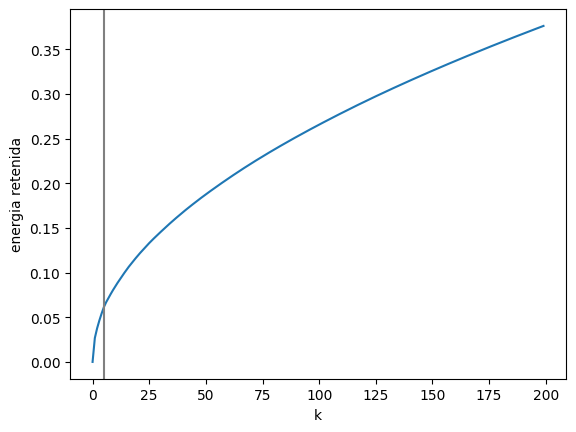

In [80]:
total = np.sum(s**2)
valores_k = [1, 2, 3, 4, 5, 6, 10, 15, 20, 30, 40, 50, 100, 200]

energias = []
errores = []

for k in valores_k:
    energia_retenida = np.sum(s[:k]**2) / total

    error_relativo = np.sqrt(np.sum(s[k:]**2) / total)

    energias.append(energia_retenida)
    errores.append(error_relativo)

# armamos una tabla con lo que salio
tabla = pd.DataFrame({
    "k": valores_k,
    "Energia retenida": energias,
    "Error relativo": errores
})

print(tabla.round(3))

# grafico de la energia retenida segun k, con una linea en el k elegido
k_elegido = 5

kas = []
for i in range(0, 200):
  kas.append(i)

retenida = []
for k in kas:
    retenida.append(np.sum(s[:k]**2) / total)

plt.plot(kas, retenida)
plt.axvline(k_elegido, linestyle="-", color="gray")
plt.xlabel("k")
plt.ylabel("energia retenida")
plt.show()

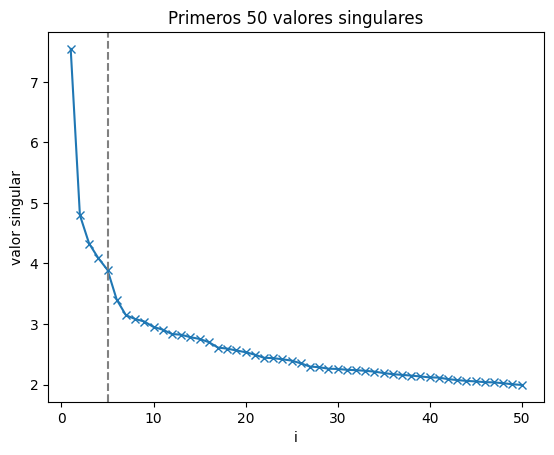

Para retener el 50.0 % de la energia se necesitan k = 351 componentes
Para retener el 75.0 % de la energia se necesitan k = 830 componentes
Para retener el 90.0 % de la energia se necesitan k = 1337 componentes


In [ ]:
asad = []
for uwu in range(1,51):
    asad.append(uwu)

plt.plot(asad ,s[:50], marker="x" ) 
plt.axvline(5, linestyle="--", color="gray")
plt.title("Primeros 50 valores singulares")
plt.xlabel("i")
plt.ylabel("valor singular")
plt.show()

total = np.sum(s**2) 
for p in [0.5, 0.75, 0.9] : 
    suma = 0
    k = 0
    for valor_singular in s:
        suma = suma + valor_singular**2 / total
        k = k + 1
        if suma >= p:
            break
    print(f"Para retener el {p*100} % de la energia se necesitan k = {k} componentes")




### ***Representacion de documentos y terminos en baja dimension***